In [21]:

import numpy as np 
import pandas as pd 
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))
import kagglehub

/kaggle/input/datasets/ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training/dirty_cafe_sales.csv


# Proyecto: Análisis de cafeteria.
**Objetivo**: 
# a)
1. ****Limpiar los datos sucios (Na, errores, desconocidos)****
2. **Rellenar vacíos en Total Spent**
3. **Parsear fechas**
4. **Utilizar SQL para conseguir información como el tipo de pedido (para llevar / en la tienda) con mejor promedio de ganancia.**


In [22]:
df = pd.read_csv('/kaggle/input/datasets/ahmedmohamed2003/cafe-sales-dirty-data-for-cleaning-training/dirty_cafe_sales.csv', encoding='latin-1')
df['date_parsed'] = pd.to_datetime(df['Transaction Date'],errors='coerce')
df['Total Spent'] = pd.to_numeric(df['Total Spent'], errors='coerce')
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Price Per Unit'] = pd.to_numeric(df['Price Per Unit'], errors='coerce')
df['Total Spent'] = df['Total Spent'].fillna(df['Quantity'] * df['Price Per Unit'])
df = df.replace(['ERROR', 'UNKNOWN'], pd.NA)
df = df.sort_values(by=['Total Spent'], ascending=False)
df['mes'] = df['date_parsed'].dt.strftime('%Y-%m')
def datos():
 mayor_ganancia = df.groupby('Item')['Total Spent'].sum().sort_values(ascending=False)
 print(f"El producto que generó más es {mayor_ganancia.idxmax()} con un total de {mayor_ganancia.max()}")
 mayor_metodo = df['Payment Method'].value_counts(normalize=True)
 print(f"El método de pago más utilizado es {mayor_metodo.idxmax()}")
datos()
#objetivo: limpiar los datos, sacar datos útiles como el método de pago mas utilizado, el producto que dió mas ganancia
#y rellenar filas vacias como total spent para no dar datos falsos

El producto que generó más es Salad con un total de 17320.0
El método de pago más utilizado es Digital Wallet


In [23]:
import duckdb

# importamos SQL:
query = """
SELECT 
    Location, 
    ROUND(AVG("Total Spent"),3) AS ticket_promedio,
    COUNT(*) AS total_ventas
FROM df
WHERE Location IS NOT NULL
GROUP BY Location
ORDER BY ticket_promedio DESC
"""

resultado_sql = duckdb.query(query).df()
print(resultado_sql)
#objetivo: conseguir informacion como el ticket promedio segun el tipo de pedido
#recomendación: impulsar la venta en in store con combos, ofertas, etc

   Location  ticket_promedio  total_ventas
0  In-store            9.033          3017
1  Takeaway            8.803          3022


In [24]:
# importamos librerias para hacer gráficos:
import matplotlib.pyplot as plt
import seaborn as sns

**Objetivo:**
# b)
1. **Crear un gráfico claro y simple, con las ganancias totales por producto.**
2. **Conseguir las ganancias cada mes y mostrarlas en un gráfico de lineas.**

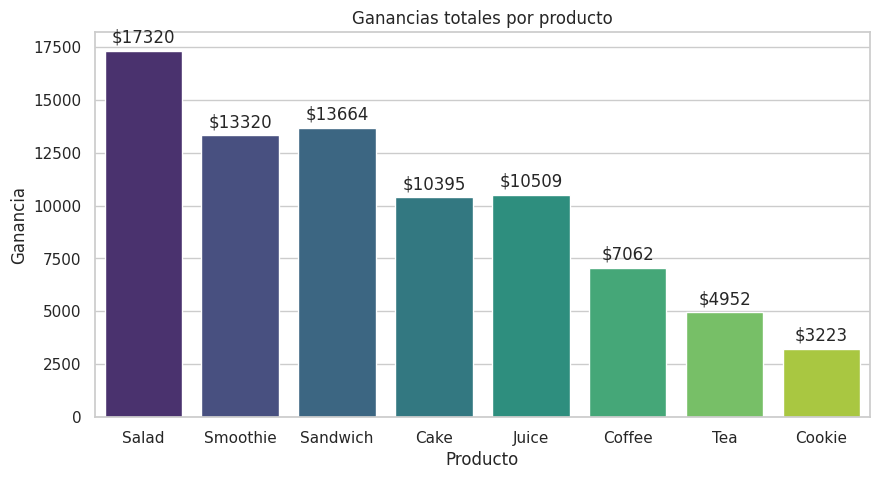

In [25]:
# creando el gráfico
plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

ax = sns.barplot(data=df, x='Item', y='Total Spent', estimator=sum, errorbar=None, palette='viridis', hue='Item', legend=False)
# por cada barra en el gráfico, dale su etiqueta:
for c in ax.containers:
    ax.bar_label(c, fmt='$%.0f', padding=3)

plt.title("Ganancias totales por producto")
plt.xlabel("Producto")
plt.ylabel("Ganancia")

# mostrando el gráfico
plt.show()
#objetivo: hacer un gráfico sencillo de entender, donde las ensaladas (Salad) lideran las ganancias totales
#recomendación: impulsar la venta de productos como café o té, con ofertas.


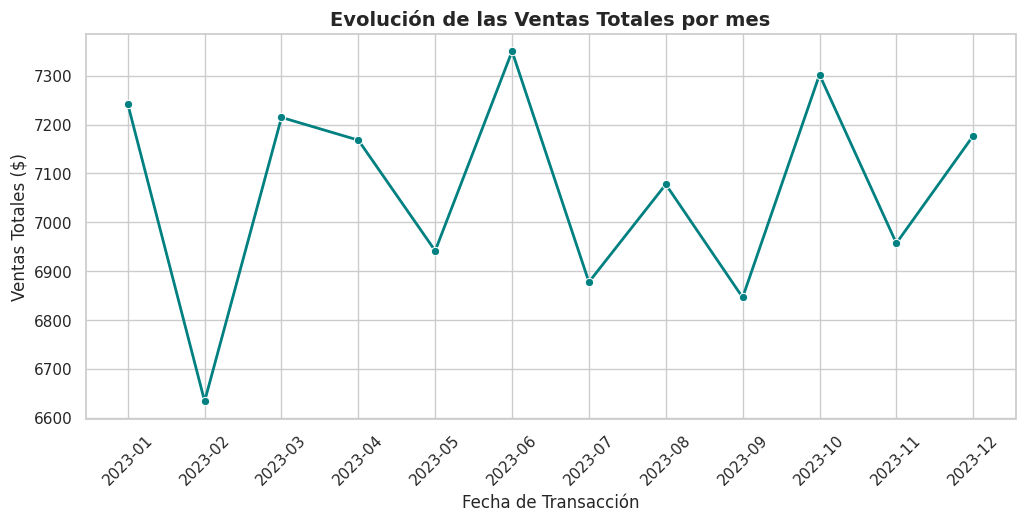

In [26]:
# grafico de crecimiento en las ventas
df_mensual = df.groupby('mes')['Total Spent'].sum().reset_index()


plt.figure(figsize=(12, 5))
sns.set_theme(style="whitegrid")

sns.lineplot(data=df_mensual, x='mes', y='Total Spent', marker='o', color='teal', linewidth=2)

plt.title("Evolución de las Ventas Totales por mes", fontsize=14, fontweight='bold')
plt.xlabel("Fecha de Transacción")
plt.ylabel("Ventas Totales ($)")

plt.xticks(rotation=45)

plt.show()
#objetivo: un gráfico que muestre las ventas de la tienda mes a mes

# **CONCLUSIONES:**
1. Con el gráfico de lineas, se ve una caída notoria en las ventas en febrero de 2023, y su pico de ventas en junio del mismo año.
2. Con el gráfico de barras, se muestra que productos como el café o galletitas son los que suelen generar menos, por lo que ofertas, combos y darle mas foco a estos productos podria aumentar los ingresos.